In [18]:
#| include: false
from pathlib import Path
from datetime import timedelta
from dataclasses import asdict
from io import BytesIO
import hashlib
import json
import sys

import pandas as pd
import matplotlib
from IPython.display import display, Image
from pandas.testing import assert_frame_equal

ROOT = next(
    (path for path in (Path.cwd(), *Path.cwd().parents)
     if (path / "pyproject.toml").is_file() and (path / "src/dp_activity").is_dir()),
    None,
)
if ROOT is None:
    raise RuntimeError("Open this notebook from within the project repository.")
if str(ROOT / "src") not in sys.path:
    sys.path.insert(0, str(ROOT / "src"))

import matplotlib.pyplot as plt
from dp_activity import StudyPeriod
from dp_activity.config import load_config
from dp_activity.cli import (
    build_download_command, _default_column_map,
    _default_classification_field_map, _snapshot_observation_end,
)
from dp_activity.repositories.raw_data_repository import RawDataRepository
from dp_activity.profiling.data_profiler import DataProfiler
from dp_activity.cleaning.permit_cleaner import PermitCleaner
from dp_activity.classification.rule_loader import RuleLoader
from dp_activity.classification.classifier import PermitClassifier
from dp_activity.validation.schema_validator import SchemaValidator
from dp_activity.validation.data_quality_validator import DataQualityValidator
from dp_activity.validation.classification_validator import ClassificationValidator
from dp_activity.features.period_features import add_period_features
from dp_activity.features.season_features import add_season_features
from dp_activity.features.processing_features import add_processing_features
from dp_activity.analysis.volume_analysis import VolumeAnalysis
from dp_activity.analysis.type_analysis import TypeAnalysis
from dp_activity.analysis.geography_analysis import GeographyAnalysis
from dp_activity.analysis.processing_analysis import ProcessingAnalysis
from dp_activity.analysis.rezoning_analysis import RezoningAnalysis
from dp_activity.analysis.seasonal_analysis import SeasonalAnalysis
from dp_activity.visualization.chart_factory import ChartFactory

pd.set_option("display.max_rows", 15)
pd.set_option("display.max_colwidth", 100)
print(f"Python {sys.version.split()[0]} | pandas {pd.__version__} | Matplotlib {matplotlib.__version__}")

Python 3.13.15 | pandas 2.2.3 | Matplotlib 3.10.8


In [19]:
#| include: false
SETTINGS_PATH = ROOT / "config/settings.yaml"
SNAPSHOT_FILENAME = "development_permits_residential_20261013_001726.parquet"
config = load_config(SETTINGS_PATH)
snapshot_path = config.raw_data_dir / SNAPSHOT_FILENAME
primary_date_field = config.raw["analysis"]["primary_date_field"]
source_date_field = next(source for source, target in _default_column_map().items() if target == primary_date_field)
expected_where = build_download_command(config).where
REVIEW_LIMIT = 5
repository = RawDataRepository(config.raw_data_dir)
raw = repository.load_snapshot(snapshot_path)
raw_before = raw.copy(deep=True)
sidecar_path = snapshot_path.with_suffix(snapshot_path.suffix + ".metadata.json")
metadata = json.loads(sidecar_path.read_text(encoding="utf-8"))
snapshot_sha256 = hashlib.sha256(snapshot_path.read_bytes()).hexdigest()
assert metadata["sha256"] == snapshot_sha256, "Snapshot checksum mismatch."
assert metadata["row_count"] == len(raw), "Snapshot row-count mismatch."
assert metadata["dataset_id"] == config.raw["data_source"]["dataset_id"]
query = metadata["query"]
if isinstance(query, str):
    query = json.loads(query)
assert query["where"] == expected_where, "Snapshot does not cover the configured query."
observation_end = _snapshot_observation_end(snapshot_path, None)
covered_periods = list(config.periods)
covered_labels = [period.name for period in covered_periods]
application_dates = pd.to_datetime(raw[source_date_field], errors="raise")
assert not raw.empty and application_dates.notna().all()
assert application_dates.dt.date.between(covered_periods[0].start, observation_end).all()
coverage_rows = []
for period in covered_periods:
    end = min(period.end, observation_end) if period.end else observation_end
    dates = application_dates.loc[application_dates.dt.date.between(period.start, end)]
    coverage_rows.append({
        "Period": period.name, "WindowStart": period.start, "WindowEnd": end,
        "ExposureDays": (end - period.start).days + 1, "AllPermitCount": len(dates),
        "FirstObservedApplication": dates.min(), "LastObservedApplication": dates.max(),
        "ContextOnly": period.end is None,
    })
coverage_table = pd.DataFrame(coverage_rows)
assert int(coverage_table["AllPermitCount"].sum()) == len(raw)
display(coverage_table)
display(pd.DataFrame([{
    "snapshot": snapshot_path.name, "records": len(raw),
    "retrieved_at_utc": metadata["retrieved_at_utc"],
    "snapshot_sha256": snapshot_sha256,
    "settings_sha256": hashlib.sha256(SETTINGS_PATH.read_bytes()).hexdigest(),
    "rules_sha256": hashlib.sha256(config.classification_rules_path.read_bytes()).hexdigest(),
}]))
print("Source-lag check: latest application date is", application_dates.max())
print("Retrieval horizon is a coverage convention, not proof of complete reporting.")

,Period,WindowStart,WindowEnd,ExposureDays,AllPermitCount,FirstObservedApplication,LastObservedApplication,ContextOnly
0,Before,2022-08-06,2024-08-05,731,16637,2022-08-06,2024-08-05,False
1,During,2024-08-06,2026-08-03,728,13866,2024-08-06,2026-08-03,False
2,Early Post-Repeal,2026-08-04,2026-10-13,71,1124,2026-08-04,2026-10-11,True


,snapshot,records,retrieved_at_utc,snapshot_sha256,settings_sha256,rules_sha256
0,development_permits_residential_20261013_001726.parquet,31627,2026-10-13 00:17:25.865806+00:00,fc7cdfad598ab894aa9eacb0cb396d4537070524d8ea8b78f4ad449b7da6e78d,5adaa64c4c2e84d942b19e50747c7b8a1e2c9e81ff96cc96887b8f25ffa46dc7,ecc20ce16844c1dbe863594a8e451e2e5c1fd6663f4926de667df62a68ccc6cb


Source-lag check: latest application date is 2026-10-11 00:00:00
Retrieval horizon is a coverage convention, not proof of complete reporting.


In [20]:
#| include: false
analysis_settings = config.raw["analysis"]
column_map = _default_column_map()
processing_settings = analysis_settings["processing_time"]
cleaned = PermitCleaner(column_map, [primary_date_field, processing_settings["end_field"]]).clean(raw)
retained_mask = raw["address"].notna() & raw["address"].astype("string").str.strip().ne("")
address_excluded_records = raw.loc[~retained_mask].copy()
assert len(cleaned) + len(address_excluded_records) == len(raw)
assert cleaned.index.equals(raw.index[retained_mask])
rules = RuleLoader().load(config.classification_rules_path)
classification_settings = analysis_settings["classification"]
classified = PermitClassifier(rules, _default_classification_field_map(), unmatched_action=classification_settings["unmatched_action"], case_sensitive=classification_settings["case_sensitive"]).classify(cleaned)
classified_before_features = classified.copy(deep=True)
observation_end = _snapshot_observation_end(snapshot_path, None)
processing_settings = analysis_settings["processing_time"]
feature_periods = list(config.periods)

period_permits = add_period_features(
    classified,
    date_column=analysis_settings["primary_date_field"],
    periods=feature_periods,
    decision_date_column=processing_settings["end_field"],
)
season_permits = add_season_features(
    period_permits,
    date_column=analysis_settings["primary_date_field"],
    season_months={
        value.get("label", key): value["months"]
        for key, value in config.raw["seasons"].items()
    },
    analysis_windows=feature_periods,
    observation_end=observation_end,
)
featured = add_processing_features(
    season_permits,
    applied_date_column=processing_settings["start_field"],
    decision_date_column=processing_settings["end_field"],
    minimum_days=processing_settings.get("minimum_days", 0),
    observation_end=observation_end,
)
assert_frame_equal(classified, classified_before_features)
assert_frame_equal(featured[classified.columns], classified)
assert_frame_equal(season_permits[period_permits.columns], period_permits)
assert_frame_equal(featured[season_permits.columns], season_permits)
assert len(featured) == len(cleaned) and featured.index.equals(cleaned.index)
assert featured["Period"].isin(covered_labels).all()


residential_permits = featured.loc[featured["IncludeResidential"]].copy()
season_definitions = {
    value.get("label", key): value["months"]
    for key, value in config.raw["seasons"].items()
}
analysis_input = featured.copy(deep=True)
strategies = [
    VolumeAnalysis(covered_periods, date_column=primary_date_field, observation_end=observation_end),
    TypeAnalysis(period_order=covered_labels),
    ProcessingAnalysis(period_order=covered_labels, community_column="community"),
    RezoningAnalysis(),
    GeographyAnalysis(
        analysis_settings["community_analysis"]["minimum_baseline_count"],
        period_order=covered_labels, community_column="community", ward_column="ward",
    ),
    SeasonalAnalysis(covered_periods, season_months=season_definitions,
                     date_column=primary_date_field, observation_end=observation_end),
]
analysis_tables = {}
for strategy in strategies:
    results = strategy.run(residential_permits)
    if set(results) & set(analysis_tables):
        raise ValueError("Analysis output names must be unique.")
    analysis_tables.update(results)
assert_frame_equal(featured, analysis_input)

residential_count = len(residential_permits)
assert_frame_equal(residential_permits, featured.loc[featured["IncludeResidential"]])
for key in ("permit_volume", "monthly_volume", "seasonal_summary", "type_summary"):
    assert int(analysis_tables[key]["PermitCount"].sum()) == residential_count
    assert set(analysis_tables[key]["Period"].dropna()) == set(covered_labels)
assert int(analysis_tables["rezoning_summary"]["PeriodResidentialCount"].sum()) == residential_count


quality_report = pd.DataFrame([asdict(item) for item in DataQualityValidator().validate(featured, settings=config.raw["quality_checks"])])
schema_issues = SchemaValidator().validate(featured, required_columns=config.raw["quality_checks"]["required_columns"])
assert not any(issue.severity == "error" for issue in schema_issues)
classification_validation = ClassificationValidator().validate(featured, rules=rules)
assert_frame_equal(raw, raw_before)
PRIMARY = covered_labels[:2]
COLORS = ["#56B4E9", "#E69F00"]
plt.style.use("dark_background")
plt.rcParams.update({"figure.figsize": (14, 5), "figure.facecolor": "#191919", "axes.facecolor": "#191919", "font.size": 18, "axes.titlesize": 20, "axes.labelsize": 18, "xtick.labelsize": 16, "ytick.labelsize": 17, "legend.fontsize": 16, "axes.spines.top": False, "axes.spines.right": False})
volume = analysis_tables["permit_volume"].set_index("Period")
primary_volume = volume.loc[PRIMARY]
count_change = (primary_volume.iloc[1]["PermitCount"] / primary_volume.iloc[0]["PermitCount"] - 1) * 100
rate_change = (primary_volume.iloc[1]["DP_Rate30"] / primary_volume.iloc[0]["DP_Rate30"] - 1) * 100
print(f"Ready: {len(raw):,} source rows; {len(address_excluded_records)} address exclusions; {len(residential_permits):,} residential applications.")

Ready: 31,627 source rows; 4 address exclusions; 18,015 residential applications.


---
title: Calgary Development Permit Before and During Blanket Rezoning
date: 2026-10-13
date-format: MMMM D, YYYY
---

## 1 · The question

**How did Calgary’s residential application activity change?**

| Study window | Dates |
|---|---|
| Before | Aug 6, 2022 – Aug 5, 2024 |
| During | Aug 6, 2024 – Aug 3, 2026 |
| Early Post-Repeal | Aug 4, 2026 onward · context only |

Applications measure planning activity, not completed homes.

::: {.notes}
**Presenter cue — 0:00–0:40; budget 0:40.**

Hello, I’m Albert Leung. This project asks how Calgary’s residential development permit application activity differed between two study windows. The Before window runs from August 6, 2022, to August 5, 2024. The During window runs from August 6, 2024, to August 3, 2026. I also show a short early post-repeal period for context. Each observation is an application record. An application can concern an existing property, so these counts do not directly measure new dwelling units or completed homes. I’ll explain the analysis, then demonstrate the Power BI report.
:::

## 2 · Why this question matters

**Permit applications provide a view of the planning process.**

- Compare volume, residential types, communities, and decision durations.
- Assign each application to its study window by application date.
- Economic conditions and other policies also changed.

**Observed differences do not establish what rezoning caused.**

::: {.source-note}
Sources: [City rezoning timeline](https://www.calgary.ca/planning/projects/rezoning.html) · [Land Use Bylaw](https://www.calgary.ca/planning/land-use/online-land-use-bylaw.html?sec=21P2024) · [Methodology](../docs/METHODOLOGY.md)
:::

::: {.notes}
**Presenter cue — 0:40–1:25; budget 0:45.**

This question matters because development permits provide a view of activity in the planning process. The rezoning timeline gives us a way to organize that activity into study windows. I compare volume, residential type, location, and recorded time to a decision. Applications are assigned to periods by their application date, even when the decision occurs later. These are observational comparisons. Housing demand, financing conditions, construction costs, and other policies may also change between windows. Therefore, a difference between Before and During does not, by itself, tell us what rezoning caused.
:::

## 3 · Data and study design

**One source row = one permit application.**

Frozen snapshot → four blank-address exclusions → residential classification.

::: {.source-note}
Source: [City of Calgary Development Permits · 6933-unw5](https://data.calgary.ca/Business-and-Economic-Activity/Development-Permits/6933-unw5). Retrieval horizon: Oct 13, 2026 UTC; latest application: Oct 11.
:::

::: {.notes}
**Presenter cue — 1:25–2:25; budget 1:00.**

The source is the City of Calgary’s Development Permits dataset, identified as 6933-unw5. I use a frozen snapshot containing 31,627 application records across the three windows. Four records are excluded because their addresses are blank or missing. Classification then identifies 18,015 residential applications: 9,856 Before, 7,603 During, and 556 in the early post-repeal window. The primary windows cover 731 and 728 days, so I compare both counts and applications per thirty exposed days. The recent window covers only 71 days and has limited decision follow-up. Its October 13, 2026 retrieval horizon describes coverage; it does not guarantee complete reporting.
:::

In [21]:
#| echo: false
from IPython.display import HTML
study_design = coverage_table[["Period", "WindowStart", "WindowEnd", "ExposureDays", "AllPermitCount"]].copy()
retained_counts = featured.groupby("Period", observed=True).size()
residential_counts = residential_permits.groupby("Period", observed=True).size()
study_design["RetainedApplications"] = study_design["Period"].map(retained_counts)
study_design["AddressExclusions"] = study_design["AllPermitCount"] - study_design["RetainedApplications"]
study_design["ResidentialApplications"] = study_design["Period"].map(residential_counts)
assert int(study_design["AllPermitCount"].sum()) == len(raw)
assert int(study_design["AddressExclusions"].sum()) == len(address_excluded_records)
assert int(study_design["ResidentialApplications"].sum()) == len(residential_permits)
display(HTML(study_design[["Period", "ExposureDays", "AllPermitCount", "ResidentialApplications"]].rename(columns={"ExposureDays": "Days", "AllPermitCount": "Source rows", "ResidentialApplications": "Residential"}).to_html(index=False, formatters={"Days": "{:,.0f}".format, "Source rows": "{:,.0f}".format, "Residential": "{:,.0f}".format})))


Period,Days,Source rows,Residential
Before,731,"16,637","9,856"
During,728,"13,866","7,603"
Early Post-Repeal,71,"1,124",556


## 4 · From source records to analysis

**Snapshot → clean → classify → validate → summarize**

- Preserve raw evidence and retained row indices.
- Exclude blank addresses; retain literal undefined values.
- Review flags request investigation, not automatic exclusion.
- Keep partial windows and processing eligibility visible.

::: {.notes}
**Presenter cue — 2:25–3:25; budget 1:00.**

The workflow moves from a frozen snapshot through cleaning, classification, feature creation, validation, and residential summaries. I preserve the original records and retained row indices so the analysis remains traceable. The cleaning rule removes four blank or missing addresses, but retains literal undefined values. Ordered rules classify residential activity, including accessory buildings and some residential non-housing applications. A review flag requests investigation; it does not automatically remove a record. Checks reconcile the totals, verify the snapshot checksum, and confirm that analysis preserves its inputs. These safeguards help reproducibility, but they do not establish independent classification accuracy or source completeness.
:::

In [22]:
#| echo: false
review_counts = pd.DataFrame({
    "Check": ["Blank-address exclusions", "Retained records needing review", "Residential records needing review"],
    "Applications": [len(address_excluded_records), int(featured["ClassificationNeedsReview"].sum()), int(residential_permits["ClassificationNeedsReview"].sum())],
})
display(HTML(review_counts.to_html(index=False, formatters={"Applications": "{:,}".format})))
print("Review flags and quality warnings remain open; checks do not certify classification accuracy.")

Check,Applications
Blank-address exclusions,4
Retained records needing review,"2,657"
Residential records needing review,539


Review flags and quality warnings remain open; checks do not certify classification accuracy.


## 5 · Volume and seasonality

**During activity is lower in both counts and exposure-adjusted rates.**

::: {.notes}
**Presenter cue — 3:25–4:40; budget 1:15.**

The main volume result is a decline from 9,856 residential applications Before to 7,603 During. That is 2,253 fewer applications, or a 22.86 percent decline. Adjusting for the slightly different window lengths, activity falls from 404.49 to 313.31 applications per thirty exposed days, a decline of 22.54 percent. The monthly chart shows that activity fluctuates within both windows. The grey recent series is context only. Boundary months can contain only part of a month, so a low fragment is not necessarily a full-month collapse. The appendix’s complete-season comparisons also show lower During rates in every season. Those rates adjust calendar exposure, but they do not remove economic differences, reporting lag, or other possible explanations.
:::

,Applications,Per 30 days
Period,,
Before,"9,856",404.49
During,"7,603",313.31


During versus Before: -22.86% applications; -22.54% applications per 30 exposed days.


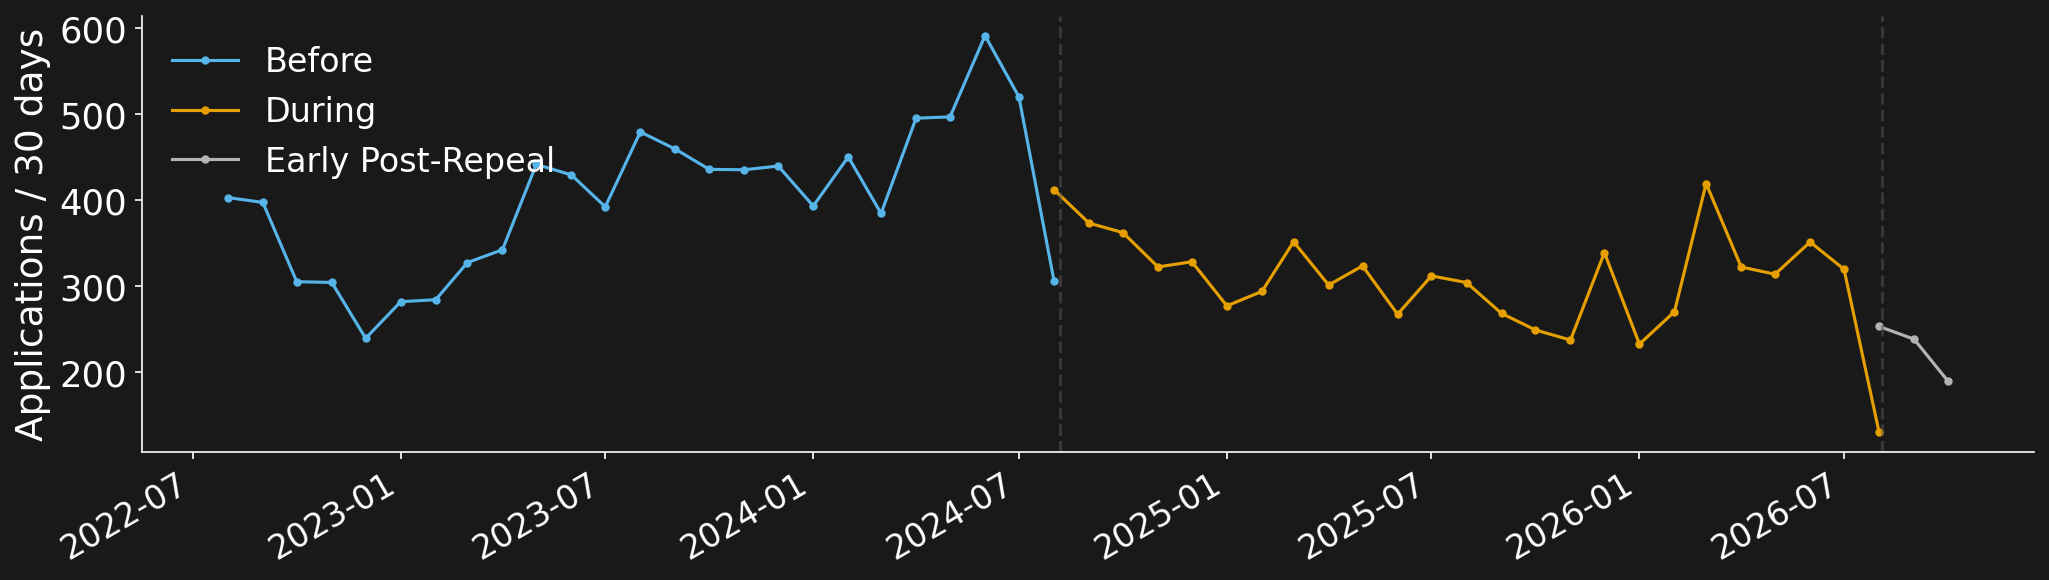

In [23]:
#| echo: false
display(HTML(primary_volume[["PermitCount", "DP_Rate30"]].rename(columns={"PermitCount": "Applications", "DP_Rate30": "Per 30 days"}).to_html(formatters={"Applications": "{:,.0f}".format, "Per 30 days": "{:,.2f}".format})))
print(f"During versus Before: {count_change:+.2f}% applications; {rate_change:+.2f}% applications per 30 exposed days.")
monthly = analysis_tables["monthly_volume"]
fig, ax = plt.subplots(figsize=(14, 4.2))
for label, color in zip(covered_labels, [*COLORS, "#B4B4B4"]):
    part = monthly.loc[monthly["Period"].eq(label)].sort_values("YearMonth")
    ax.plot(pd.to_datetime(part["YearMonth"]), part["DP_Rate30"].astype(float), marker=".", label=label, color=color)
for boundary in (covered_periods[1].start, covered_periods[2].start):
    ax.axvline(pd.Timestamp(boundary), color="#555555", linestyle="--", alpha=.5)
ax.set(ylabel="Applications / 30 days", xlabel="")
ax.legend(frameon=False)
fig.autofmt_xdate()
plt.tight_layout()
chart_buffer = BytesIO()
fig.savefig(chart_buffer, format="png", dpi=150, bbox_inches="tight")
display(Image(data=chart_buffer.getvalue()))
plt.close(fig)
complete = analysis_tables["seasonal_summary"].loc[lambda table: table["IsCompleteSeason"] & table["Period"].isin(PRIMARY)]
season_rates = complete.groupby(["Period", "Season"], observed=True)[["PermitCount", "ExposureDays"]].sum()
season_rates["DP_Rate30"] = season_rates["PermitCount"] / season_rates["ExposureDays"] * 30

## 6 · Which residential types changed?

**Read counts alongside shares: a larger share can accompany fewer applications.**

::: {.notes}
**Presenter cue — 4:40–5:40; budget 1:00.**

The overall decline is not shared equally by every residential type. Secondary Suite has the largest decline: 2,660 fewer applications. Backyard Suite has the largest increase: 280 more applications. Townhouse applications also increase, by 254. Counts and shares answer different questions. For example, Multi-Residential declines by 58 applications while its share rises by about 0.58 percentage points, because the total residential denominator falls. I therefore read counts alongside shares rather than treating a larger share as proof of more activity. These labels are rule-based analytical categories. They describe application activity and cannot be converted directly into numbers of new homes.
:::

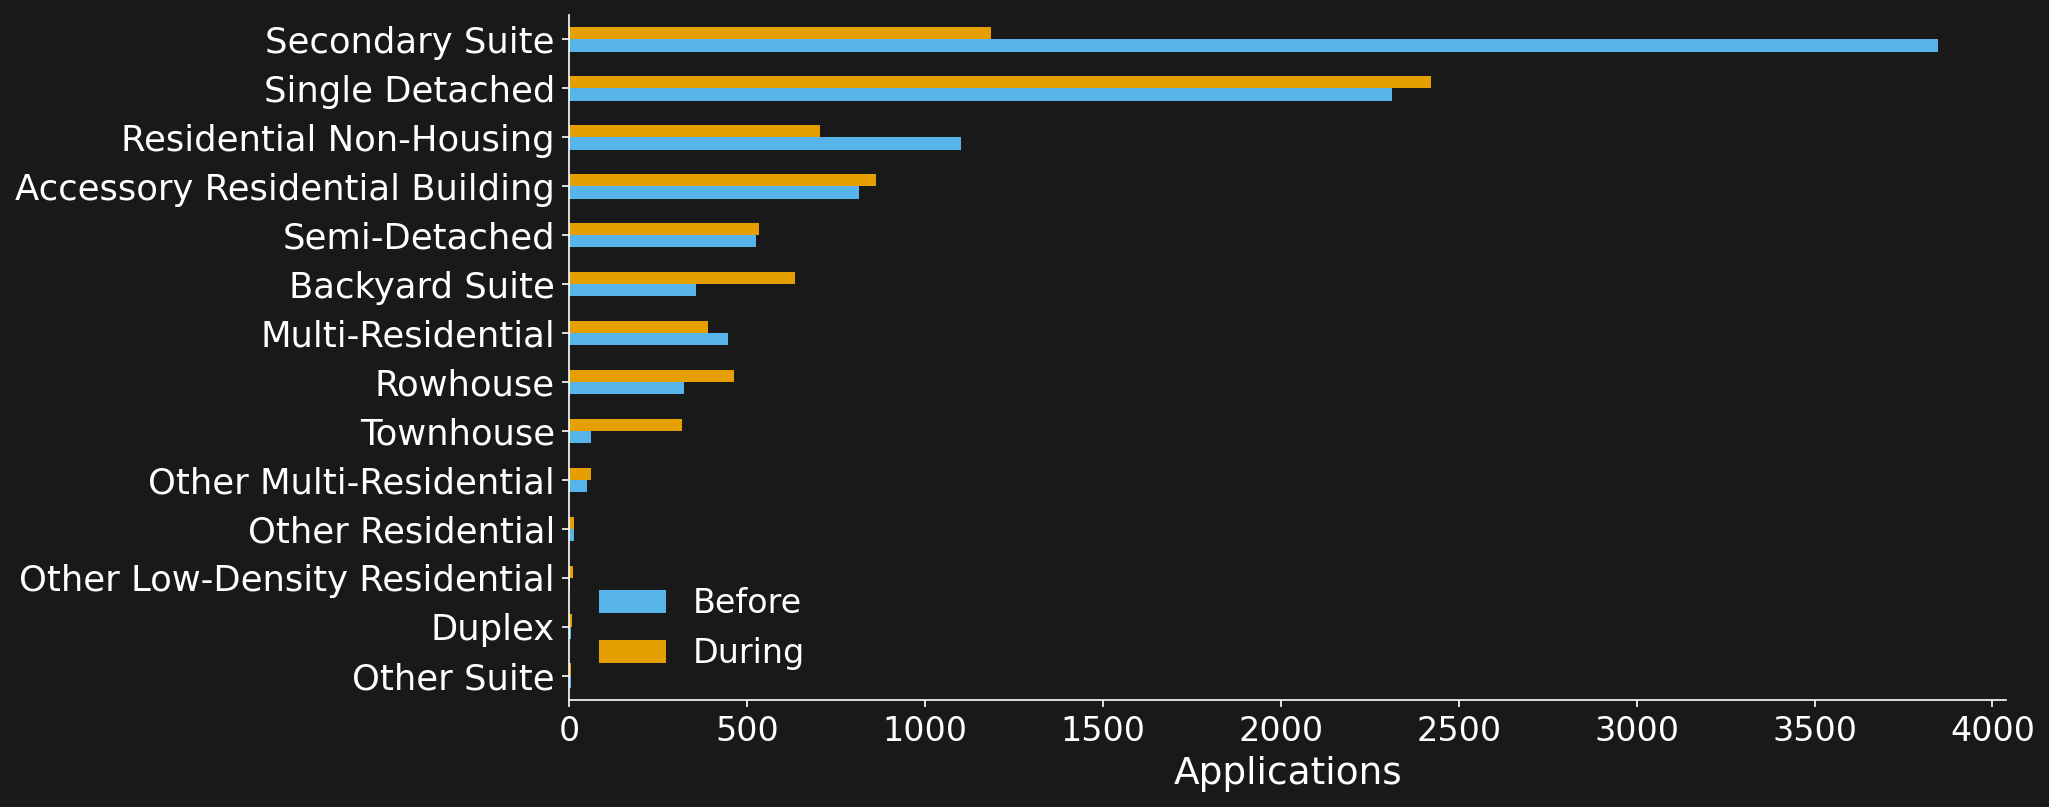

Largest type decline: Secondary Suite (-2,660 applications).
Largest type increase: Backyard Suite (+280 applications).


In [24]:
#| echo: false
type_table = analysis_tables["type_summary"]
type_counts = type_table.loc[type_table["Period"].isin(PRIMARY)].pivot(index="ResidentialType", columns="Period", values="PermitCount").reindex(columns=PRIMARY).fillna(0)
type_counts = type_counts.loc[type_counts.sum(axis=1).sort_values().index]
fig, ax = plt.subplots(figsize=(14, 5.7))
type_counts.plot.barh(ax=ax, color=COLORS)
ax.set(xlabel="Applications", ylabel="")
ax.legend(frameon=False)
plt.tight_layout()
chart_buffer = BytesIO()
fig.savefig(chart_buffer, format="png", dpi=150, bbox_inches="tight")
display(Image(data=chart_buffer.getvalue()))
plt.close(fig)
type_comparison = type_table.loc[type_table["Period"].eq(PRIMARY[1]), ["ResidentialType", "PermitCount", "AbsoluteChange", "TypeShare", "ShareChangePercentagePoints"]].copy()
type_comparison["TypeShare"] = type_comparison["TypeShare"] * 100

largest_decline = type_comparison.loc[type_comparison["AbsoluteChange"].idxmin()]
largest_increase = type_comparison.loc[type_comparison["AbsoluteChange"].idxmax()]
print(f"Largest type decline: {largest_decline['ResidentialType']} ({int(largest_decline['AbsoluteChange']):+,} applications).")
print(f"Largest type increase: {largest_increase['ResidentialType']} ({int(largest_increase['AbsoluteChange']):+,} applications).")

## 7 · Where, and how long?

**Community patterns vary; decision durations describe eligible records.**

::: {.notes}
**Presenter cue — 5:40–6:50; budget 1:10.**

The geography chart shows the ten largest absolute community changes among known communities with adequate Before baselines. It is a selected ranking, not the full distribution across Calgary. I use the source community and ward values, retain missing geography in the denominators, and flag baselines below five applications. Processing results also require careful denominators. The median recorded eligible duration rises from 41 days Before to 61 days During. Those medians use 8,231 and 5,812 eligible records; another 1,625 and 1,791 records are ineligible. The recent period has only 169 eligible records out of 556, so its eleven-day median cannot establish faster overall processing. I’ll now use Power BI to show how a viewer can explore these patterns.
:::

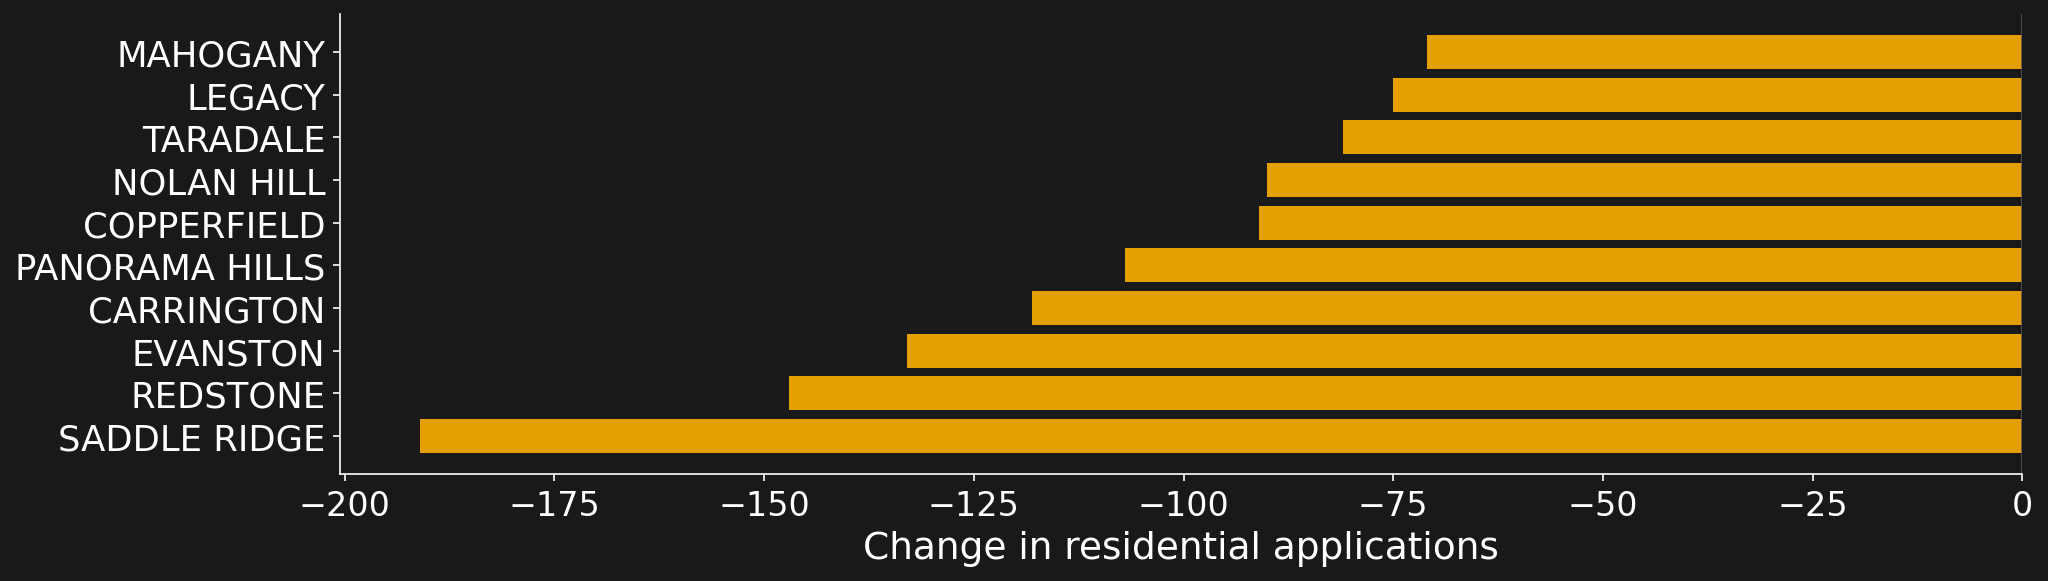

Period,Eligible,Ineligible,Median days
Before,"8,231","1,625",41
During,"5,812","1,791",61


Top 10 absolute changes; known communities with Before ≥ 5. Source geography.


In [25]:
#| echo: false
geography = analysis_tables["community_summary"]
changes = geography.loc[geography["Period"].eq(PRIMARY[1]) & ~geography["IsMissingGeography"] & ~geography["SmallBaselineWarning"]].copy()
changes = changes.loc[changes["AbsoluteChange"].abs().nlargest(10).index].sort_values("AbsoluteChange")
fig, ax = plt.subplots(figsize=(14, 4.2))
ax.barh(changes["Community"], changes["AbsoluteChange"].astype(float), color=[COLORS[1] if value < 0 else COLORS[0] for value in changes["AbsoluteChange"]])
ax.axvline(0, color="#555555", linewidth=.8)
ax.set(xlabel="Change in residential applications", ylabel="")
plt.tight_layout()
chart_buffer = BytesIO()
fig.savefig(chart_buffer, format="png", dpi=150, bbox_inches="tight")
display(Image(data=chart_buffer.getvalue()))
plt.close(fig)
processing_display = analysis_tables["processing_summary"].loc[lambda table: table["Period"].isin(PRIMARY), ["Period", "ValidCount", "InvalidCount", "MedianProcessingDays"]].rename(columns={"ValidCount": "Eligible", "InvalidCount": "Ineligible", "MedianProcessingDays": "Median days"})
display(HTML(processing_display.to_html(index=False, formatters={"Eligible": "{:,.0f}".format, "Ineligible": "{:,.0f}".format, "Median days": "{:.0f}".format})))
print("Top 10 absolute changes; known communities with Before ≥ 5. Source geography.")

## Live Power BI demonstration

**Explore the report: overall activity → residential types → community differences.**

- Overview: monthly application counts and a type filter.
- Development Type & Processing: counts and eligible durations.
- Geography: Before/During comparison and baseline warnings.

::: {.notes}
**Presenter cue — 6:50–8:50; exactly two minutes including clicks.** Switch to the already-open report. Speak only the quoted paragraphs; bracketed text gives actions. At 8:50 return to slide 8. Use the appendix checklist before presenting.

**6:50–7:25 | Overview | 35 seconds**

[Switch to Power BI Desktop, with `Data 110 - visualization.pbix` already open on **Overview**. Start with cleared slicers and no selected chart marks. Point to the Residential Permits card and monthly line; select **Backyard Suite** in the ResidentialType slicer, pause for the visuals, then clear that slicer.]

“This is the Overview page. The monthly line shows application counts; it is different from the notebook’s applications per thirty exposed days. I’ll select Backyard Suite to explore that category, then clear the selection to restore the broader view. The monthly-average visuals use their own denominator, so I do not treat them as exposure-adjusted rates. The recent post-repeal observations remain context only.”

**7:25–8:05 | Development Type & Processing | 40 seconds**

[Open **Development Type & Processing**. Clear this page’s slicers and chart selections; use its Period slicer to keep **Before** and **During** only. Hover a Secondary Suite count bar. Point to the type/period matrix and its **Valid Count Dynamic**, **Valid Share Dynamic**, and **Median Processing Days Dynamic** values. Do not rely on the percentage-of-grand-total visual as a within-period type share.]

“This page compares residential types and recorded processing durations. Secondary Suite is the largest decline in the notebook, while Backyard Suite increases. I use the count chart to inspect those differences. For processing, I read the median alongside the valid count and valid share in the matrix. A median based on eligible decisions describes that observed subset; it does not summarize all pending applications. The notebook’s period medians are forty-one days Before and sixty-one days During.”

**8:05–8:40 | Geography | 35 seconds**

[Open **Geography**. Clear its ward, season, and residential-type slicers and chart selections. Hover one visible community in the Before/During count chart; point to the comparison table’s **Before**, **During**, **Raw Change**, **Raw Change %**, and **Baseline** columns. Use the table if the map is slow; do not wait for it.]

“This page compares Before and During by community. I’ll inspect one community and read its two counts, absolute change, and baseline warning together. A large percentage change can come from a small starting count. The table also provides thirty-day rates, which answer a different question from raw counts. A map helps locate activity, but the table gives the evidence needed to interpret the comparison.”

**8:40–8:50 | Return | 10 seconds**

[Switch back to the deck and advance to **8 · Conclusions and limits**.]

“Power BI makes these comparisons explorable. Agreement with the notebook still needs verification for the imported dataset. I’ll finish with the conclusions and limitations.”

**If an interaction fails:** Say, “I’ll use the existing chart and table to explain the comparison.” Continue to the next timed step. Do not troubleshoot during the talk. If Power BI cannot open, use the prepared screenshots and the same narration. Skip the type-filter action and say, “This view can be filtered to a residential type.”

**If behind schedule:** Show Overview and Geography only; omit the Development Type & Processing segment and return to slide 8 by 8:50. Optional community drill-through is for questions after the ten-minute talk, not this demo.
:::

## 8 · Conclusions and limits

**During had fewer residential applications; subgroup patterns varied.**

- Compare counts with shares and baseline sizes.
- Read decision durations with eligible counts and follow-up.
- Early Post-Repeal remains contextual.

**Still needed:** classification review, sensitivity checks, and Power BI reconciliation.

::: {.notes}
**Presenter cue — 8:50–9:40; budget 0:50.**

To conclude, the During window contains fewer residential applications, with a 22.54 percent lower rate per thirty exposed days. Type and community patterns vary, so the citywide total does not describe every subgroup. Eligible recorded processing durations also differ, but incomplete decisions and unequal follow-up limit that comparison. The frozen snapshot, checksums, reconciliation, and visible eligibility counts make the workflow traceable. Independent classification review, sensitivity analysis, and verification of the imported Power BI results are still needed before stronger claims. The early post-repeal window remains contextual. These findings describe observed application activity; they do not establish a causal policy effect. Thank you.
:::

In [26]:
#| echo: false
print(f"{int(volume.loc[PRIMARY[0], 'PermitCount']):,} Before → {int(volume.loc[PRIMARY[1], 'PermitCount']):,} During")
print(f"Applications: {count_change:+.2f}%  |  Per 30 exposed days: {rate_change:+.2f}%")
print("Observational differences do not establish a causal policy effect.")

9,856 Before → 7,603 During
Applications: -22.86%  |  Per 30 exposed days: -22.54%
Observational differences do not establish a causal policy effect.


## Appendix · sources and reproducibility

**Outside the ten-minute talk**

- [Complete exploration and review register](02_complete_period_exploration.ipynb)
- [Verified findings and workflow](02_complete_period_exploration_explanation.md)
- [Methodology](../docs/METHODOLOGY.md) · [Bias and mitigation](../docs/BIAS_AND_MITIGATION.md)
- [Classification rules](../docs/CONFIGURATION.md) · [References](../docs/REFERENCES.md)
- [Power BI guide](../docs/POWER_BI_PLAN.md)

To refresh: retain the snapshot sidecar, rerun all cells, and review reconciliation,
classification warnings, and eligible processing counts before rendering.



## Appendix · complete-season rates

**Pooled applications per 30 exposed days; complete seasons only.**

In [27]:
#| echo: false
display(HTML(season_rates["DP_Rate30"].unstack("Period").reindex(columns=PRIMARY).to_html(float_format="{:.2f}".format)))
print("Complete seasons only; pooled applications per 30 exposed days.")

Period,Before,During
Season,,
Fall,389.01,301.81
Spring,414.29,338.64
Summer,433.37,294.46
Winter,347.73,290.17


Complete seasons only; pooled applications per 30 exposed days.


## Appendix · residential type changes

**During counts, change from Before, and within-period share.**

In [28]:
#| echo: false
type_slide_table = type_comparison.rename(columns={"ResidentialType": "Residential type", "PermitCount": "During", "AbsoluteChange": "Count change", "TypeShare": "Share (%)", "ShareChangePercentagePoints": "Share Δ (pp)"}).sort_values("Count change")
type_slide_table["Share (%)"] = type_slide_table["Share (%)"].map("{:.2f}".format)
type_slide_table["Share Δ (pp)"] = type_slide_table["Share Δ (pp)"].map("{:+.2f}".format)
display(HTML(type_slide_table.to_html(index=False, formatters={"During": "{:,.0f}".format, "Count change": "{:+,.0f}".format})))

Residential type,During,Count change,Share (%),Share Δ (pp)
Secondary Suite,"1,186","-2,660",15.60,-23.42
Residential Non-Housing,705,-397,9.27,-1.91
Multi-Residential,389,-58,5.12,+0.58
Other Suite,3,+0,0.04,+0.01
Other Residential,14,+2,0.18,+0.06
Duplex,7,+2,0.09,+0.04
Other Low-Density Residential,10,+8,0.13,+0.11
Semi-Detached,533,+8,7.01,+1.68
Other Multi-Residential,61,+13,0.80,+0.32
Accessory Residential Building,862,+48,11.34,+3.08


## Appendix · rehearsal timing

**7:40 narration + 2:00 demonstration + 0:20 buffer = 10:00**

| Section | Talk clock |
|---|---|
| 1 · Question | 0:00–0:40 |
| 2 · Context | 0:40–1:25 |
| 3 · Study design | 1:25–2:25 |
| 4 · Preparation | 2:25–3:25 |
| 5 · Volume | 3:25–4:40 |
| 6 · Types | 4:40–5:40 |
| 7 · Geography and processing | 5:40–6:50 |
| Power BI demo | 6:50–8:50 |
| 8 · Conclusion | 8:50–9:40 |

::: {.notes}
**Detailed rehearsal checklist · outside the ten-minute talk**

**Timing: 7:40 slide narration + 2:00 live demonstration + 0:20 buffer = 10:00.** Use the buffer for the title, app switching, or a short pause. It is not a reserved question period.

| Segment | Talk clock | Budget |
|---|---|---|
| 1 · The question | 0:00–0:40 | 0:40 |
| 2 · Why this question matters | 0:40–1:25 | 0:45 |
| 3 · Data and study design | 1:25–2:25 | 1:00 |
| 4 · Source to analysis | 2:25–3:25 | 1:00 |
| 5 · Volume and seasonality | 3:25–4:40 | 1:15 |
| 6 · Residential types | 4:40–5:40 | 1:00 |
| 7 · Geography and processing | 5:40–6:50 | 1:10 |
| Live Power BI demonstration | 6:50–8:50 | 2:00 |
| 8 · Conclusions and limits | 8:50–9:40 | 0:50 |
| Title / transition / pause buffer | Up to 10:00 | 0:20 |

### Before the audience arrives

1. Open [the saved Power BI report](../powerbi/Data%20110%20-%20visualization.pbix) and the deck. Let the visuals finish loading. Avoid refreshing or importing data during the talk.
2. Clear slicers and chart selections on each demo page. Rehearse selecting and clearing **Backyard Suite** on **Overview**. On **Development Type & Processing**, rehearse selecting **Before** and **During** together in the Period slicer and locating the count chart and processing matrix.
3. Check the report’s imported workbook and snapshot provenance. For the notebook’s pinned snapshot and current rules, unfiltered residential counts should reconcile to **18,015 total: 9,856 Before, 7,603 During, 556 Early Post-Repeal**. Check eligible processing counts **8,231 / 5,812 / 169** and medians **41 / 61 / 11 days** for the corresponding periods. Record discrepancies rather than claiming agreement. Report-definition inspection alone does not verify rendered values or filter behavior.
4. Keep the same report state for rehearsal and presentation. Selecting a type, season, ward, or community changes the filter context; do not describe a filtered value as a citywide total. The Overview monthly count and monthly-average measures are not the notebook’s **DP_Rate30**. The type percentage-of-grand-total visual is not automatically a within-period type share.
5. Save screenshots of the three report pages as a backup. Choose one visible community with a usable Before baseline for the Geography hover. Map coordinates can involve report-specific location logic; the notebook’s community analysis uses source geography.
6. Rehearse once with a stopwatch, including clicks. Speak at roughly 110–125 words per minute and use remaining time to point and pause. Begin the demo at **6:50**, return by **8:50**, and finish the conclusion by **9:40**. If late, use the shortened demo route in its notes.
7. The word-for-word scripts are inside each slide’s `::: {.notes}` block, including the demo slide. Read them here or in the rendered deck’s speaker-notes view. Bracketed demo instructions and presenter cues are not spoken.

**Evidence boundary:** Speaker-note numbers match the notebook’s saved outputs for `development_permits_residential_20261013_001726.parquet`. After changing data, settings, or rules, rerun and update the spoken numbers. The Power BI script is based on the committed report pages and visual definitions; live interaction and imported-data reconciliation have not been tested as part of this notes-only edit.
:::

## Appendix · prepare the live demonstration

- Open the report and deck; let all visuals load before the talk.
- Clear slicers and chart selections on all three demo pages.
- Rehearse Backyard Suite selection and reset on Overview.
- Check Before/During selection and eligible processing values.
- Choose a Geography hover with a usable Before baseline.
- Save screenshots as a backup; avoid refreshes during delivery.

**Start the demo at 6:50; return to the conclusion by 8:50.**

## Appendix · verify before presenting

| Check | Before | During | Context only |
|---|---:|---:|---:|
| Residential applications | 9,856 | 7,603 | 556 |
| Eligible processing records | 8,231 | 5,812 | 169 |
| Median eligible days | 41 | 61 | 11 |

- Reconcile Power BI under matching filters; record discrepancies.
- Counts, monthly averages, and 30-day rates use different denominators.
- Rerun after changing the snapshot, settings, or classification rules.
- Rehearse with a stopwatch, including clicks and app switching.

**Saved notebook outputs support these values; report interactions require testing.**